# Haapsalu urban blocks

Self-study project: city blocks and block metrics for Haapsalu (Estonia) with BlocksNet,
and a comparison of OpenStreetMap buildings with official Estonian building data.
See `PLAN.md` for the research questions.

## 1. Data

This section downloads every input layer, brings it to the Estonian metric
coordinate system **EPSG:3301 (L-EST97)**, cuts it to the town boundary and saves it to
`data/*.geojson`. Large raw downloads go to `data/raw/` (not in git).
At the end it writes `data/SOURCES.md` and a check map `data/check_map.png`.

### 1.0 Set-up

Libraries, folders and the download date. Every layer is registered in `SOURCES`,
which is used at the end to write `data/SOURCES.md`.

In [1]:
import json
import time
import urllib.parse
import urllib.request
from datetime import date
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx as ox
import pandas as pd
from shapely import force_2d

CRS = "EPSG:3301"  # L-EST97, Estonian metric CRS
DATA = Path("data")
RAW = DATA / "raw"
RAW.mkdir(parents=True, exist_ok=True)
TODAY = date.today().isoformat()

ox.settings.use_cache = True
ox.settings.cache_folder = str(RAW / "osmnx_cache")

SOURCES = []  # one dict per saved layer or table


def download(url, path):
    """Download url to path once; later runs reuse the file."""
    path = Path(path)
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path


def save_layer(gdf, name, source, url, licence):
    """Save a layer as data/<name>.geojson and register it in SOURCES."""
    gdf = gdf.to_crs(CRS)
    path = DATA / f"{name}.geojson"
    gdf.to_file(path, driver="GeoJSON")
    SOURCES.append(dict(layer=name, file=str(path.as_posix()), source=source, url=url,
                        licence=licence, date=TODAY, features=len(gdf)))
    print(f"{name}: {len(gdf)} features -> {path}")
    return gdf

### 1.1 Town boundary (official)

Source: Maa- ja Ruumiamet, EHAK administrative and settlement division, layer
"Asustusüksused" (settlement units). We take the settlement **Haapsalu linn**
(EHAK code 1692), not the municipality Haapsalu linn, which since 2017 also includes
the former Ridala vald. The file is already in EPSG:3301.

In [2]:
EHAK_URL = "https://s3.pilw.io/rp-kemit-kataster/EHAK/asustusyksus_shp.zip"
ehak_zip = download(EHAK_URL, RAW / "asustusyksus_shp.zip")

settlements = gpd.read_file(f"zip://{ehak_zip.as_posix()}!asustusyksus.shp")
boundary = settlements[settlements["AKOOD"] == "1692"].to_crs(CRS)
assert len(boundary) == 1 and boundary.iloc[0]["ANIMI"] == "Haapsalu linn"
boundary = boundary[["ANIMI", "AKOOD", "ONIMI", "OKOOD", "EKSPORT", "geometry"]]
boundary["EKSPORT"] = boundary["EKSPORT"].astype(str)

save_layer(boundary, "boundary", "Maa- ja Ruumiamet, EHAK settlement units (Asustusüksused), "
           f"Haapsalu linn, AKOOD 1692, export {boundary.iloc[0]['EKSPORT'][:10]}",
           EHAK_URL, "Maa- ja Ruumiamet open data licence (CC BY 4.0 equivalent)")
print(f"Area: {boundary.area.iloc[0] / 1e6:.2f} km²")

area = boundary.geometry.iloc[0]          # boundary polygon in EPSG:3301
area_wgs = boundary.to_crs(4326).geometry.iloc[0]  # the same in WGS84, for OSM queries

boundary: 1 features -> data\boundary.geojson
Area: 11.02 km²


### 1.2 OpenStreetMap layers

Downloaded with `osmnx` for the boundary polygon, using the same tags as the BlocksNet
example `examples/pipeline.ipynb`. Lines and areas (roads, water, land use) are cut
exactly at the boundary. Buildings and schools are **not cut**: an object is kept whole
if its inside point lies in the town, so footprint areas stay correct for the comparison
with the official buildings. Only useful columns are kept.

In [3]:
OSM_URL = "https://www.openstreetmap.org (Overpass API via osmnx)"
OSM_LICENCE = "ODbL 1.0, © OpenStreetMap contributors"


def osm(tags, geom_types, columns, cut=True, attempts=6):
    """Fetch OSM features inside the boundary, keep given geometry types and columns.

    The public Overpass server is sometimes busy, so failed requests are retried
    with a growing pause (30 s, 60 s, 120 s, ...).
    """
    for i in range(attempts):
        try:
            gdf = ox.features_from_polygon(area_wgs, tags)
            break
        except ox._errors.InsufficientResponseError:
            return gpd.GeoDataFrame(columns=["osm_id", *columns, "geometry"], geometry="geometry", crs=CRS)
        except ox._errors.ResponseStatusCodeError as e:
            if i == attempts - 1:
                raise
            print(f"Overpass busy, retry in {30 * 2 ** i} s: {str(e)[:60]}")
            time.sleep(30 * 2 ** i)
    gdf = gdf.reset_index()
    gdf["osm_id"] = gdf["element"] + "/" + gdf["id"].astype(str)
    gdf = gdf[gdf.geom_type.isin(geom_types)]
    gdf = gdf[["osm_id", *[c for c in columns if c in gdf.columns], "geometry"]].to_crs(CRS)
    if cut:
        gdf = gdf.clip(area)
        gdf = gdf[~gdf.is_empty]
    else:
        gdf = gdf[gdf.representative_point().within(area)]
    return gdf.reset_index(drop=True)


LINES = ["LineString", "MultiLineString"]
POLYS = ["Polygon", "MultiPolygon"]

Tags from the BlocksNet example: roads, railways and water.

**Railway is excluded from block cutting.** The Haapsalu line is closed, but OSM still has
a few segments tagged `railway=rail` near the old station. They are saved to
`data/osm_railways.geojson` for transparency, and `RAILWAYS_FOR_CUTTING` is an empty layer,
so the closed line does not split blocks in section 2.

In [4]:
road_tags = {"highway": ["construction", "crossing", "living_street", "motorway", "motorway_link",
                         "motorway_junction", "pedestrian", "primary", "primary_link", "raceway",
                         "residential", "road", "secondary", "secondary_link", "services", "tertiary",
                         "tertiary_link", "track", "trunk", "trunk_link", "turning_circle",
                         "turning_loop", "unclassified"],
             "service": ["living_street", "emergency_access"]}
water_tags = {"riverbank": True, "reservoir": True, "basin": True, "dock": True, "canal": True,
              "pond": True, "natural": ["water", "bay"], "waterway": ["river", "canal", "ditch"],
              "landuse": "basin", "water": "lake"}

roads = osm(road_tags, LINES, ["highway", "service", "name"])
railways = osm({"railway": "rail"}, LINES, ["railway", "name"])
water = osm(water_tags, POLYS + LINES, ["natural", "water", "waterway", "landuse", "name"])

save_layer(roads, "osm_roads", "OpenStreetMap, highway=* (BlocksNet example tags)", OSM_URL, OSM_LICENCE)
save_layer(railways, "osm_railways", "OpenStreetMap, railway=rail (closed line; not used for block cutting)",
           OSM_URL, OSM_LICENCE)
RAILWAYS_FOR_CUTTING = railways.iloc[0:0]  # the Haapsalu line is closed: no railway lines cut blocks
save_layer(water, "osm_water", "OpenStreetMap, water tags from the BlocksNet example", OSM_URL, OSM_LICENCE);

osm_roads: 697 features -> data\osm_roads.geojson
osm_railways: 4 features -> data\osm_railways.geojson
osm_water: 61 features -> data\osm_water.geojson


Land use (`landuse=*`), buildings (`building=*`, with `building:levels`) and schools
(`amenity=school`).

In [5]:
landuse = osm({"landuse": True}, POLYS, ["landuse", "name"])
buildings_osm = osm({"building": True}, POLYS,
                    ["building", "building:levels", "height", "name", "addr:street", "addr:housenumber"],
                    cut=False)
schools_osm = osm({"amenity": "school"}, POLYS + ["Point"], ["amenity", "name", "isced:level", "capacity"],
                  cut=False)

# Remove duplicates: a school polygon lying inside another school polygon with the same name
# (Haapsalu Põhikool is mapped twice: the school grounds and, inside them, a second outline).
key = schools_osm["name"].str.lower()
duplicate = [i for i, g in schools_osm.geometry.items() if g.geom_type != "Point" and any(
    j != i and key[j] == key[i] and h.geom_type != "Point" and h.area > g.area and h.buffer(1).contains(g)
    for j, h in schools_osm.geometry.items())]
print("Removed OSM school duplicates:", schools_osm.loc[duplicate, ["osm_id", "name"]].values.tolist())
schools_osm = schools_osm.drop(index=duplicate).reset_index(drop=True)

save_layer(landuse, "osm_landuse", "OpenStreetMap, landuse=*", OSM_URL, OSM_LICENCE)
save_layer(buildings_osm, "osm_buildings", "OpenStreetMap, building=* (whole buildings, inside point in town)",
           OSM_URL, OSM_LICENCE)
save_layer(schools_osm, "osm_schools", "OpenStreetMap, amenity=school", OSM_URL, OSM_LICENCE);

Removed OSM school duplicates: [['way/859053315', 'Haapsalu põhikool']]
osm_landuse: 344 features -> data\osm_landuse.geojson
osm_buildings: 3885 features -> data\osm_buildings.geojson


osm_schools: 4 features -> data\osm_schools.geojson


### 1.3 Official buildings (ETAK + Building Register)

Source: Maa- ja Ruumiamet WFS, layer `etak_tuletis:etak_ehr_hooned`: ETAK building
footprints enriched with Building Register (EHR) data, including the number of floors
`max_korruste_arv`, height, footprint and net floor area, and use. Only the bounding box
of Haapsalu is requested (in pages of 5 000, the server limit), then buildings whose
inside point lies in the town are kept. Heights in the geometry (Z) are dropped.

In [6]:
WFS = "https://gsavalik.envir.ee/geoserver/etak_tuletis/wfs"
xmin, ymin, xmax, ymax = boundary.total_bounds
pages, start = [], 0
while True:
    url = (f"{WFS}?service=WFS&version=2.0.0&request=GetFeature&typeNames=etak_tuletis:etak_ehr_hooned"
           f"&srsName=EPSG:3301&outputFormat=application/json&sortBy=fid&count=5000&startIndex={start}"
           f"&bbox={xmin:.0f},{ymin:.0f},{xmax:.0f},{ymax:.0f},EPSG:3301")
    with urllib.request.urlopen(url) as r:
        page = json.load(r)
    pages += page["features"]
    start += len(page["features"])
    if len(page["features"]) < 5000:
        break

(RAW / "etak_ehr_hooned_bbox.geojson").write_text(
    json.dumps({"type": "FeatureCollection", "features": pages}), encoding="utf-8")
buildings_off = gpd.GeoDataFrame.from_features(pages, crs=CRS)
buildings_off["geometry"] = force_2d(buildings_off.geometry)
print(f"In bounding box: {len(buildings_off)}")
buildings_off = buildings_off[buildings_off.representative_point().within(area)].reset_index(drop=True)

save_layer(buildings_off, "official_buildings",
           "Maa- ja Ruumiamet, WFS etak_tuletis:etak_ehr_hooned (ETAK buildings with EHR data), "
           "Haapsalu bounding box, inside point in town",
           WFS, "Maa- ja Ruumiamet open data licence (CC BY 4.0 equivalent)");

In bounding box: 4560


official_buildings: 3941 features -> data\official_buildings.geojson


### 1.4 Statistics Estonia (census 2021)

Tables from the Statistics Estonia database (PxWeb API) for the settlement unit
Haapsalu linn (code `005601841692L5`), state on 31 December 2021:

- **RL21003**: population by place of residence (settlement), sex and age. Gives the total
  population and the number of children aged 7–18.
- **RL21218**: total area of occupied conventional dwellings.
- **RL21807**: "average area of dwelling per inhabitant" (kept for comparison only).

**Which area per person is used.** The census defines the area of a dwelling in two ways:
the useful floor area inside the outer walls, or the floor area of rooms only. Two published
figures differ a lot: the census results page "Housing arrangements" gives **30.1 m²** per
person for Estonia, RL21807 gives **23.5 m²**. The 30.1 m² figure is the total useful floor
area: it matches the RL21218 total (38.97 million m², the "nearly 39 million m²" on the
results page) divided by the residents. RL21807 is about 78 % of that in every area we
checked, which fits the floor area of rooms only (no kitchen, bathroom, hall); its table has
no footnote saying so, so this part is an inference. BlocksNet estimates population from
footprint × floors, a gross floor area, so the total useful floor area is closer. For
Haapsalu linn it is RL21218 occupied dwelling area / RL21003 population. The denominator
also includes people in institutions, so the value is slightly low (the same calculation
gives 29.3 m² for Estonia against the published 30.1 m²).

In [7]:
STAT = "https://andmed.stat.ee/api/v1/en/stat/"
T_POP = "rahvaloendus/rel2021/rahvastiku_paiknemine/elukoht-ja-soo-vanusjaotus/RL21003.px"
T_AREA = "rahvaloendus/rel2021/elamistingimused/RL21807.px"
HAAPSALU = "005601841692L5"


def pxweb(table, selection):
    body = {"query": [{"code": k, "selection": {"filter": "item", "values": v}} for k, v in selection.items()],
            "response": {"format": "json-stat2"}}
    req = urllib.request.Request(STAT + table, json.dumps(body).encode(), {"Content-Type": "application/json"})
    with urllib.request.urlopen(req) as r:
        return json.load(r)


with urllib.request.urlopen(STAT + T_POP) as r:
    ages = {v: t for v, t in zip(*[(x["values"], x["valueTexts"]) for x in json.load(r)["variables"]
                                   if x["code"] == "Vanus"][0])}
pop = pxweb(T_POP, {"Sugu": ["1"], "Elukoht": [HAAPSALU], "Vanus": list(ages)})
by_age = dict(zip(pop["dimension"]["Vanus"]["category"]["index"], pop["value"]))
population = by_age["1"]  # "Age total"
children_7_18 = sum(n for code_, n in by_age.items() if ages[code_].isdigit() and 7 <= int(ages[code_]) <= 18)

places = {"1": "Estonia", "00560000000000": "Lääne county", "00560184000001": "Haapsalu municipality",
          HAAPSALU: "Haapsalu linn (settlement)"}
area_tab = pxweb(T_AREA, {"Elukoht": list(places), "Rahvus": ["1"], "Leibkonna suurus": ["1"],
                          "Näitaja": ["1"], "Sugu": ["1"], "Vanus": ["1"]})
idx = area_tab["dimension"]["Elukoht"]["category"]["index"]
rooms_area_per_person = {places[k]: area_tab["value"][i] for k, i in idx.items()}

T_DWELL = "rahvaloendus/rel2021/eluruumid/RL21218.px"
dwell = pxweb(T_DWELL, {"Asukoht": [HAAPSALU, "1"], "Asustatus": ["2"], "Hoone tüüp": ["1"], "Tehnovarustatus": ["1"]})
dwell = {k: dwell["value"][i] for k, i in dwell["dimension"]["Asukoht"]["category"]["index"].items()}
estonia_pop = pxweb(T_POP, {"Sugu": ["1"], "Elukoht": ["1"], "Vanus": ["1"]})["value"][0]

LIVING_AREA_PER_PERSON = round(dwell[HAAPSALU] / population, 1)  # m², used in section 2

statistics = {
    "population_haapsalu_linn_2021": population,
    "children_7_18_haapsalu_linn_2021": children_7_18,
    "occupied_dwelling_area_m2_2021": {"Haapsalu linn (settlement)": dwell[HAAPSALU], "Estonia": dwell["1"]},
    "living_area_per_person_m2_used": LIVING_AREA_PER_PERSON,
    "living_area_per_person_method": "RL21218 occupied conventional dwelling area / RL21003 population, Haapsalu linn",
    "check_estonia_same_method_m2": round(dwell["1"] / estonia_pop, 1),
    "published_estonia_total_area_per_person_m2": 30.1,
    "rl21807_area_per_inhabitant_m2_not_used": rooms_area_per_person,
    "tables": {"RL21003": STAT + T_POP, "RL21218": STAT + T_DWELL, "RL21807": STAT + T_AREA,
               "housing_arrangements_page": "https://rahvaloendus.ee/en/results/housing-arrangements"},
    "reference_date": "2021-12-31", "download_date": TODAY,
}
(DATA / "statistics.json").write_text(json.dumps(statistics, indent=2, ensure_ascii=False), encoding="utf-8")
SOURCES.append(dict(layer="statistics", file="data/statistics.json",
                    source="Statistics Estonia, census 2021, tables RL21003, RL21218 and RL21807",
                    url=STAT, licence="Statistics Estonia terms of use (free use with source reference)",
                    date=TODAY, features=None))
statistics

{'population_haapsalu_linn_2021': 9595,
 'children_7_18_haapsalu_linn_2021': 1188,
 'occupied_dwelling_area_m2_2021': {'Haapsalu linn (settlement)': 286529,
  'Estonia': 38970750},
 'living_area_per_person_m2_used': 29.9,
 'living_area_per_person_method': 'RL21218 occupied conventional dwelling area / RL21003 population, Haapsalu linn',
 'check_estonia_same_method_m2': 29.3,
 'published_estonia_total_area_per_person_m2': 30.1,
 'rl21807_area_per_inhabitant_m2_not_used': {'Estonia': 23.5,
  'Lääne county': 25.1,
  'Haapsalu municipality': 24.1,
  'Haapsalu linn (settlement)': 22.7},
 'tables': {'RL21003': 'https://andmed.stat.ee/api/v1/en/stat/rahvaloendus/rel2021/rahvastiku_paiknemine/elukoht-ja-soo-vanusjaotus/RL21003.px',
  'RL21218': 'https://andmed.stat.ee/api/v1/en/stat/rahvaloendus/rel2021/eluruumid/RL21218.px',
  'RL21807': 'https://andmed.stat.ee/api/v1/en/stat/rahvaloendus/rel2021/elamistingimused/RL21807.px',
  'housing_arrangements_page': 'https://rahvaloendus.ee/en/results/

### 1.5 Schools: number of students (EHIS)

Source: Estonian Education Information System (EHIS) open data, service
`opilastearvud` (student numbers per school and grade) on 1 October 2026. The service
gives the number of students, not the design capacity, so the number of students is used
as the school capacity. Students are summed over grades; the separate count
"tugi olemas" (students with support) is a subset and is not added.

Location: the EHIS open data service `hooned` gives the school buildings with coordinates
(L-EST97); the main building (`peahoone = jah`) is used. A school without buildings there
is located by its legal address with the Maa- ja Ruumiamet address service In-ADS.

Selection: start from schools with a legal address in the municipality Haapsalu linn.
**Used** are only general-education schools whose main building lies inside the settlement
boundary. Excluded: Haapsalu Kutsehariduskeskus (vocational), and schools outside the town
(Uuemõisa Lasteaed-Algkool in Uuemõisa alevik, Ridala Põhikool in Panga küla). All are kept
in `data/ehis_schools.csv` with the reason; the used ones go to `data/schools.geojson`.

In [8]:
EHIS_DATE = "01.10.2026"
EHIS_URL = f"http://enda.ehis.ee/avaandmed/rest/opilastearvud/{EHIS_DATE}/JSON"
ehis_raw = download(EHIS_URL, RAW / f"ehis_opilastearvud_{EHIS_DATE}.json")
records = json.loads(ehis_raw.read_text(encoding="utf-8"))["body"]["opilastearvud"]["opilastearv"]

rows = []
for r in records:
    addr = r.get("juriidilineAadress", {})
    if addr.get("kov") != "Haapsalu linn" or r.get("tyyp") not in ("põhikool või gümnaasium", "kutseõppeasutus"):
        continue
    grades = [x for x in r["arvud"] if "klassVoiTase" in x]
    rows.append(dict(name=r["nimetus"], reg_nr=r["regNr"], ehis_id=r["koolId"], type=r.get("tyyp"),
                     subtype=r.get("alamTyyp", ""), address=addr.get("aadress", "").replace("|", " ").split(),
                     postcode=addr.get("sihtnumber"), students=sum(int(x["arv"]) for x in grades),
                     general_school=r.get("tyyp") == "põhikool või gümnaasium"))
ehis = pd.DataFrame(rows)
ehis["address"] = ehis["address"].str.join(" ")

# School main buildings with coordinates (EHIS open data, service "hooned")
import xml.etree.ElementTree as ET
from shapely.geometry import Point

HOONED_URL = "http://enda.ehis.ee/avaandmed/rest/hooned"
hooned_raw = download(HOONED_URL, RAW / "ehis_hooned.xml")
main_building = {}
for k in ET.parse(hooned_raw).getroot().iter("kool"):
    for h in k.iter("hoone"):
        if h.findtext("peahoone") == "jah" and h.findtext("koordinaatX"):
            # koordinaatX is the northing, koordinaatY the easting (L-EST97)
            main_building[k.findtext("oppeasutusId")] = (float(h.findtext("koordinaatY")),
                                                        float(h.findtext("koordinaatX")), h.findtext("aadress"))

INADS = "https://inaadress.maaamet.ee/inaadress/gazetteer"


def geocode(address):
    """Locate an address with In-ADS (Maa- ja Ruumiamet); returns (x, y, full address)."""
    url = INADS + "?" + urllib.parse.urlencode({"address": address, "results": 1})
    with urllib.request.urlopen(url) as r:
        a = json.load(r)["addresses"][0]
    return float(a["viitepunkt_x"]), float(a["viitepunkt_y"]), a["pikkaadress"]


points, how = [], []
for r in ehis.itertuples():
    if r.ehis_id in main_building:
        x, y, full = main_building[r.ehis_id]
        how.append("EHIS hooned, main building: " + full)
    else:
        x, y, full = geocode(f"{r.address}, Haapsalu linn")
        how.append("In-ADS geocoding: " + full)
    points.append(Point(x, y))
ehis = gpd.GeoDataFrame(ehis, geometry=points, crs=CRS)
ehis["location_source"] = how
ehis["inside_town"] = ehis.within(area)
ehis["used"] = ehis["general_school"] & ehis["inside_town"]
ehis["note"] = ehis.apply(lambda r: "used" if r.used else
                          "vocational school, not general education" if not r.general_school else
                          "outside Haapsalu linn settlement", axis=1)
ehis = ehis.sort_values(["used", "students"], ascending=False).reset_index(drop=True)

ehis.drop(columns="geometry").assign(x=ehis.geometry.x.round(1), y=ehis.geometry.y.round(1)).to_csv(
    DATA / "ehis_schools.csv", index=False)
SOURCES.append(dict(layer="ehis_schools", file="data/ehis_schools.csv",
                    source=f"EHIS open data, services opilastearvud ({EHIS_DATE}) and hooned; "
                           "all schools with legal address in Haapsalu linn municipality, with reason used / not used",
                    url=f"{EHIS_URL}; {HOONED_URL}", licence="EHIS open data (andmed.eesti.ee); licence to be confirmed",
                    date=TODAY, features=len(ehis)))
schools = save_layer(ehis[ehis["used"]], "schools",
                     "EHIS general-education schools inside Haapsalu linn, students as capacity (main building points)",
                     f"{EHIS_URL}; {HOONED_URL}", "EHIS open data (andmed.eesti.ee); licence to be confirmed")
ehis.drop(columns="geometry")

schools: 5 features -> data\schools.geojson


,name,reg_nr,ehis_id,type,subtype,address,postcode,students,general_school,location_source,inside_town,used,note
0,Haapsalu Põhikool,75012966,388,põhikool või gümnaasium,põhikool,Lihula mnt 12,90507,598,True,"EHIS hooned, main building: Lääne maakond, Haa...",True,True,used
1,Läänemaa Ühisgümnaasium,75038167,3551,põhikool või gümnaasium,gümnaasium,F. J. Wiedemanni tn 15,90503,304,True,"EHIS hooned, main building: Lääne maakond, Haa...",True,True,used
2,Haapsalu Linna Algkool,75012952,387,põhikool või gümnaasium,põhikool,Ehte tn 14,90502,282,True,"EHIS hooned, main building: Lääne maakond, Haa...",True,True,used
3,Haapsalu Viigi Kool,70005660,814,põhikool või gümnaasium,põhikool,Suur-Mere tn 17,90502,89,True,"EHIS hooned, main building: Lääne maakond, Haa...",True,True,used
4,Haapsalu Montessori Kool,80650545,2162466,põhikool või gümnaasium,põhikool,Jaama tn 15,90507,8,True,"In-ADS geocoding: Lääne maakond, Haapsalu linn...",True,True,used
5,Haapsalu Kutsehariduskeskus,70003796,51,kutseõppeasutus,,Ehitajate tee 3,90401,426,False,"EHIS hooned, main building: Lääne maakond, Haa...",False,False,"vocational school, not general education"
6,Uuemõisa Lasteaed-Algkool,75022485,566,põhikool või gümnaasium,lasteaed-põhikool,Lossi tänav 4,90401,153,True,"EHIS hooned, main building: Lääne maakond, Haa...",False,False,outside Haapsalu linn settlement
7,Ridala Põhikool,75022508,568,põhikool või gümnaasium,lasteaed-põhikool,Kooli tn 4,90402,135,True,"EHIS hooned, main building: Lääne maakond, Haa...",False,False,outside Haapsalu linn settlement


### 1.6 Summary

Number of features per layer, and how many buildings have a number of floors:
`building:levels` in OSM, `max_korruste_arv` in the official layer.

In [9]:
summary = pd.DataFrame([s for s in SOURCES if s["features"] is not None])[["layer", "features"]]
osm_levels = pd.to_numeric(buildings_osm["building:levels"], errors="coerce") if "building:levels" in buildings_osm else pd.Series(dtype=float)
floors = pd.DataFrame([
    dict(layer="osm_buildings", buildings=len(buildings_osm), with_floors=int(osm_levels.notna().sum())),
    dict(layer="official_buildings", buildings=len(buildings_off),
         with_floors=int(buildings_off["max_korruste_arv"].notna().sum())),
])
floors["share_%"] = (100 * floors["with_floors"] / floors["buildings"]).round(1)
display(summary)
display(floors)

,layer,features
0,boundary,1
1,osm_roads,697
2,osm_railways,4
3,osm_water,61
4,osm_landuse,344
5,osm_buildings,3885
6,osm_schools,4
7,official_buildings,3941
8,ehis_schools,8
9,schools,5


,layer,buildings,with_floors,share_%
0,osm_buildings,3885,140,3.6
1,official_buildings,3941,2982,75.7


### 1.7 `data/SOURCES.md`

One row per layer or table: source, URL, licence, download date and number of features.

In [10]:
lines = ["# Data sources", "",
         "Generated by `notebook.ipynb`, section 1. All layers are in EPSG:3301 (L-EST97).", "",
         "| Layer | File | Source | URL | Licence | Downloaded | Features |",
         "| --- | --- | --- | --- | --- | --- | --- |"]
for s in SOURCES:
    n = "" if s["features"] is None else s["features"]
    lines.append(f"| {s['layer']} | `{s['file']}` | {s['source']} | {s['url']} | {s['licence']} | {s['date']} | {n} |")
lines += ["", "Number of floors in building layers:", "",
          "| Layer | Buildings | With floors | Share, % |", "| --- | --- | --- | --- |"]
lines += [f"| {r.layer} | {r.buildings} | {r.with_floors} | {r._4} |" for r in floors.itertuples()]
lines += ["", "## Notes and decisions", "",
          f"- **Living area per person: {LIVING_AREA_PER_PERSON} m²** (Haapsalu linn, census 2021) = RL21218 total area "
          f"of occupied conventional dwellings ({dwell[HAAPSALU]:,} m²) / RL21003 population ({population:,}). "
          "This is the total useful floor area of dwellings, the same concept as the 30.1 m² for Estonia on the census "
          "page \"Housing arrangements\" (https://rahvaloendus.ee/en/results/housing-arrangements). It is the closest "
          "to BlocksNet's footprint × floors (gross floor area). The same calculation gives "
          f"{statistics['check_estonia_same_method_m2']} m² for Estonia, slightly below 30.1 m², because people in "
          "institutions are in the denominator. RL21807 (23.5 m² Estonia, "
          f"{rooms_area_per_person['Haapsalu linn (settlement)']} m² Haapsalu linn) is not used: it is about 78 % of "
          "the total area, which fits the floor area of rooms only (inferred; the table has no footnote).",
          "- **Railway:** `osm_railways` contains segments of the closed Haapsalu line; they are not used for block cutting.",
          "- **Schools:** only general-education schools inside Haapsalu linn are used (`schools.geojson`). "
          "Excluded: Haapsalu Kutsehariduskeskus (vocational), Uuemõisa Lasteaed-Algkool (Uuemõisa alevik) and "
          "Ridala Põhikool (Panga küla), both outside the settlement. EHIS gives students, not design capacity; "
          "students are used as capacity.",
          "- **OSM schools:** the duplicate outline of Haapsalu Põhikool inside its school grounds is removed.",
          "- **Buildings** (both layers) are kept whole if their inside point lies in the town, not cut at the boundary."]
(DATA / "SOURCES.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\n".join(lines))

# Data sources

Generated by `notebook.ipynb`, section 1. All layers are in EPSG:3301 (L-EST97).

| Layer | File | Source | URL | Licence | Downloaded | Features |
| --- | --- | --- | --- | --- | --- | --- |
| boundary | `data/boundary.geojson` | Maa- ja Ruumiamet, EHAK settlement units (Asustusüksused), Haapsalu linn, AKOOD 1692, export 2026-09-02 | https://s3.pilw.io/rp-kemit-kataster/EHAK/asustusyksus_shp.zip | Maa- ja Ruumiamet open data licence (CC BY 4.0 equivalent) | 2026-10-30 | 1 |
| osm_roads | `data/osm_roads.geojson` | OpenStreetMap, highway=* (BlocksNet example tags) | https://www.openstreetmap.org (Overpass API via osmnx) | ODbL 1.0, © OpenStreetMap contributors | 2026-10-30 | 697 |
| osm_railways | `data/osm_railways.geojson` | OpenStreetMap, railway=rail (closed line; not used for block cutting) | https://www.openstreetmap.org (Overpass API via osmnx) | ODbL 1.0, © OpenStreetMap contributors | 2026-10-30 | 4 |
| osm_water | `data/osm_water.geojson` | OpenStreetMap, wate

### 1.8 Check map

Boundary, roads, water and both building layers, side by side, saved to
`data/check_map.png` for a visual check before building blocks. EHIS schools are shown on
both maps: used (inside the town) and excluded. Ridala Põhikool is about 13 km south and
falls outside the map frame.

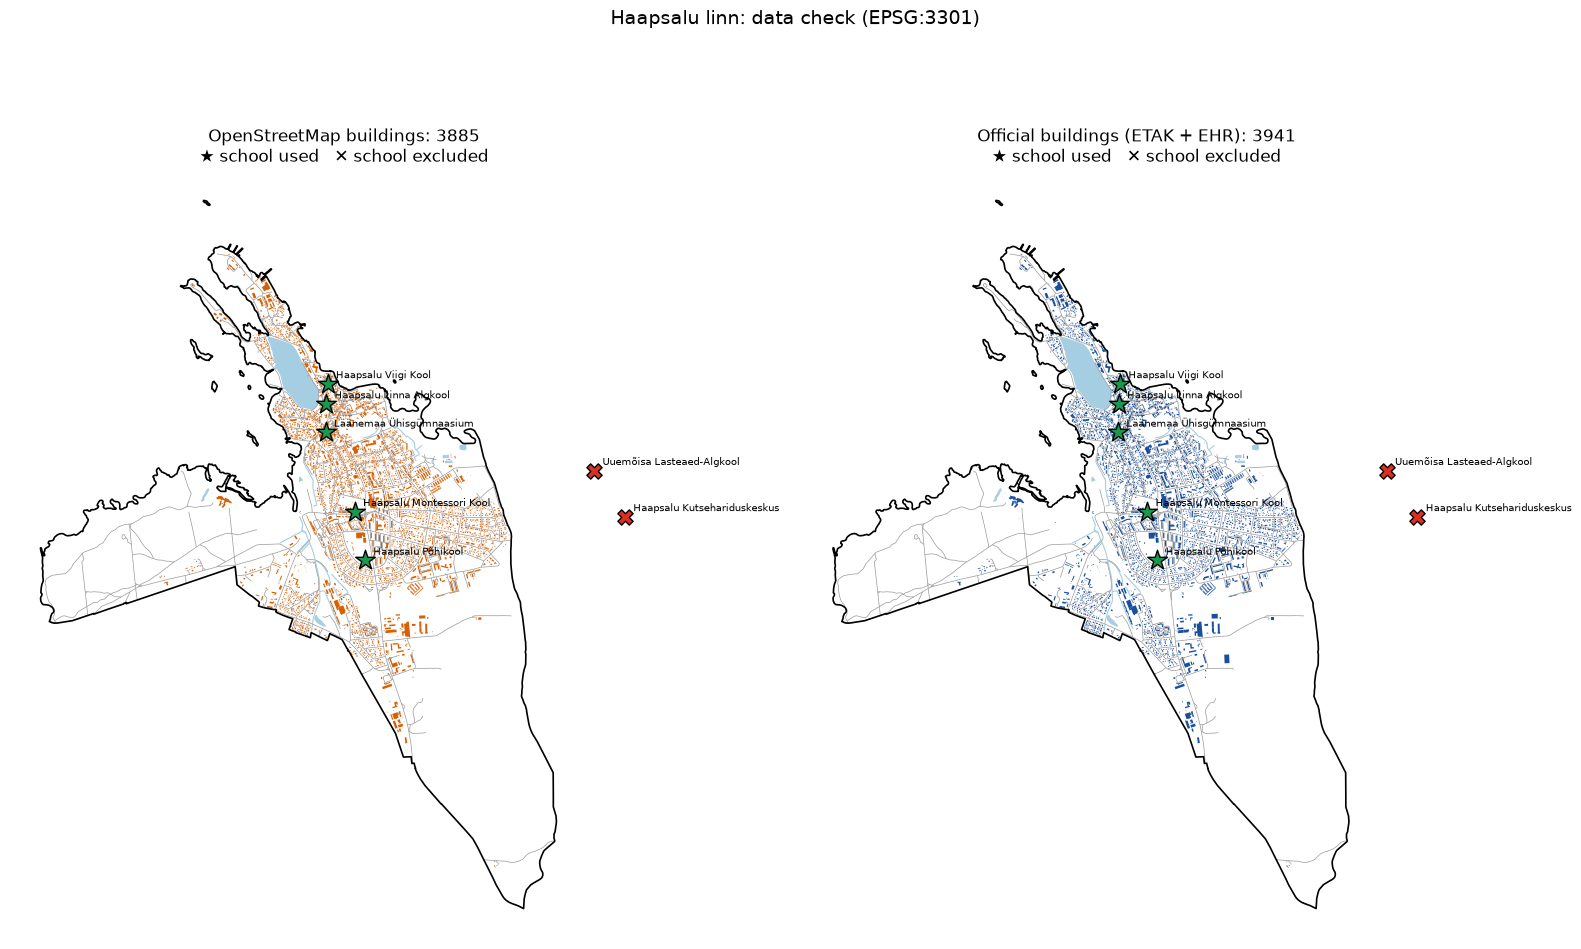

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 11), sharex=True, sharey=True)
xmin, ymin, xmax, ymax = boundary.total_bounds
for ax, (title, b, colour) in zip(axes, [("OpenStreetMap buildings", buildings_osm, "#d95f02"),
                                         ("Official buildings (ETAK + EHR)", buildings_off, "#1b4f9c")]):
    water.plot(ax=ax, color="#a6cee3", edgecolor="#a6cee3", linewidth=0.8)
    roads.plot(ax=ax, color="#999999", linewidth=0.5)
    b.plot(ax=ax, color=colour, linewidth=0)
    boundary.boundary.plot(ax=ax, color="black", linewidth=1.2)
    ehis[ehis["used"]].plot(ax=ax, color="#1a9850", marker="*", markersize=220, edgecolor="black", zorder=5)
    ehis[~ehis["used"]].plot(ax=ax, color="#d73027", marker="X", markersize=120, edgecolor="black", zorder=5)
    for r in ehis.itertuples():
        ax.annotate(r.name, (r.geometry.x, r.geometry.y), xytext=(6, 4), textcoords="offset points", fontsize=7)
    ax.set_xlim(xmin - 300, xmax + 1200)
    ax.set_ylim(ymin - 300, ymax + 300)
    ax.set_title(f"{title}: {len(b)}\n★ school used   ✕ school excluded")
    ax.set_axis_off()
fig.suptitle("Haapsalu linn: data check (EPSG:3301)", fontsize=14)
fig.tight_layout()
fig.savefig(DATA / "check_map.png", dpi=150)
plt.show()